# TOPIC 1: Explainable Machine Learning for Gallstone Disease
**Member 2 Scope:** Explainability (XAI) of the selected model with SHAP and LIME, and clinical interpretation of the results.

This notebook continues `eda_and_models.ipynb` (Member 1). It loads the exported pipeline `best_model.joblib` (ColumnTransformer + XGBoost, selected by mean F1-score in Stratified 5-Fold Cross-Validation) and answers the second objective of the project: **which clinical characteristics contribute most to the model's predictions?**

## Index of the Notebook
1. **Setup:** libraries, data loading and reconstruction of the same train/test split used by Member 1.
2. **Sanity check:** the exported pipeline reproduces the holdout results of Member 1.
3. **SHAP global explanations:** beeswarm (summary) plot and bar plot.
4. **SHAP local explanations:** waterfall plots for three selected test patients (true positive, false negative, false positive).
5. **SHAP dependence plots** for the most important features.
6. **LIME local explanations** for the same three patients, compared with SHAP.
7. **Robustness of the ranking:** SHAP vs permutation importance vs Logistic Regression coefficients vs a single Decision Tree.
8. **Clinical interpretation and contrast with the literature.**
9. **Limitations** (including the correlation between body-composition features).

**Encoding reminder (from Member 1):** in the original dataset `Gallstone Status` is 0 = gallstones present, 1 = absent. For modelling it was recoded so that **1 = Disease (gallstones)** and **0 = Healthy**. Therefore a **positive SHAP value pushes the prediction towards gallstone disease**.

In [1]:
# NECESSARY LIBRARIES
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, roc_auc_score, accuracy_score, confusion_matrix,
                             precision_score, recall_score)

# Explainability libraries (pip install shap lime)
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings('ignore')
np.random.seed(42)

# folder where the figures for the report and the slides are saved
fig_dir = os.path.join('..', 'figures')
os.makedirs(fig_dir, exist_ok=True)

print(f"shap {shap.__version__}")

shap 0.54.1


## 1. Setup: data loading and the same train/test split

The exported pipeline does not store `X_train` / `X_test`, so we rebuild them with **exactly the same code and seed** as Member 1 (`test_size=0.20`, `stratify=y`, `random_state=42`). Explanations are computed on the **64 holdout test patients**, which the model never saw during training.

In [2]:
#loading the dataset (same file and engine as Member 1)
data_path = os.path.join('..', 'dataset', 'dataset-uci.xlsx')
df = pd.read_excel(data_path, engine='calamine')

target_col = 'Gallstone Status'
X = df.drop(columns=[target_col])

#recoding: 1 = Disease (gallstones), 0 = Healthy
y = (df[target_col] == 0).astype(int)

#same stratified split as Member 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Disease patients in test set: {y_test.sum()} of {len(y_test)}")

Train: (255, 38), Test: (64, 38)
Disease patients in test set: 32 of 64


## 2. Sanity check: the exported pipeline

Before explaining the model we check that the pipeline we loaded is the same one Member 1 evaluated. The holdout F1-score of XGBoost should be **0.7692**.

Besides accuracy, F1 and ROC-AUC we report the metrics derived from the confusion matrix, because in a medical problem the two types of error are not equally serious:

- **Precision** = TP / (TP + FP): of the patients flagged as disease, how many really have gallstones.
- **Recall (sensitivity)** = TP / (TP + FN): of the patients with gallstones, how many the model detects. A **false negative** is a sick patient sent home, the most dangerous error.
- **Specificity** = TN / (TN + FP): of the patients without gallstones, how many are correctly classified. A **false positive** leads to unnecessary further tests.

In [3]:
#loading the fitted pipeline (ColumnTransformer + XGBoost)
model_path = os.path.join('..', 'dataset', 'best_model.joblib')
best_pipeline = joblib.load(model_path)

preprocessor = best_pipeline.named_steps['preprocessor']
xgb_model = best_pipeline.named_steps['classifier']

#predictions on the holdout test set
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]   # probability of Disease (class 1)

print(f"Holdout Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Holdout F1-Score: {f1_score(y_test, y_pred):.4f}  (expected 0.7692)")
print(f"Holdout ROC-AUC:  {roc_auc_score(y_test, y_proba):.4f}")

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"\nConfusion matrix: TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Precision:            {precision_score(y_test, y_pred):.4f}")
print(f"Recall (sensitivity): {recall_score(y_test, y_pred):.4f}")
print(f"Specificity:          {tn / (tn + fp):.4f}")

Holdout Accuracy: 0.7656
Holdout F1-Score: 0.7692  (expected 0.7692)
Holdout ROC-AUC:  0.8477

Confusion matrix: TN=24  FP=8  FN=7  TP=25
Precision:            0.7576
Recall (sensitivity): 0.7812
Specificity:          0.7500


### Feature names and original values

The `ColumnTransformer` **reorders the columns**: first the 33 standardized continuous features, then the 5 binary features (passthrough). SHAP works on this transformed matrix, so we keep the feature names in that same order.

The model sees standardized values (z-scores), which are hard to read clinically. Standardization is a monotonic transformation per feature, so the SHAP values are the same; for the plots we show the **original clinical values** (e.g. CRP in mg/L) in the same column order.

In [4]:
#names in the order produced by the ColumnTransformer (remove 'num__' / 'remainder__')
raw_names = preprocessor.get_feature_names_out()
feature_names = [n.split('__', 1)[1] for n in raw_names]

#transformed test matrix = what the XGBoost classifier actually receives
X_test_transformed = preprocessor.transform(X_test)

#original (unscaled) values reordered to match the transformed matrix
X_test_original = X_test[feature_names]

print(f"{len(feature_names)} features, first five: {feature_names[:5]}")

38 features, first five: ['Age', 'Comorbidity', 'Height', 'Weight', 'Body Mass Index (BMI)']


## 3. SHAP global explanations

**What is being explained.** XGBoost is an ensemble of many small **decision trees**. Each tree splits the patients with questions of the form "is CRP > 1.2?", choosing at every node the split that best separates the classes (the same idea as choosing the split with the highest information gain in a single decision tree, but XGBoost measures the gain with the reduction of the training error). Every tree is added to correct the mistakes of the previous ones, and the prediction is the **sum of the scores of all the trees**.

That sum is not a probability but a **log-odds** score z. The model turns it into a probability with the **sigmoid function**, P(disease) = 1 / (1 + e^(-z)): z = 0 means 50%, positive z means more than 50% and negative z less than 50%. Because the sigmoid is increasing, anything that raises z raises the probability of disease.

We use `shap.TreeExplainer`, the exact and fast SHAP algorithm for tree ensembles such as XGBoost. For each patient and each feature it gives a SHAP value: how much that feature moved the model output z (in log-odds of Disease) away from the average prediction. The SHAP values of one patient add up exactly to the difference between that patient's z and the average z, so a positive SHAP value pushes the probability of gallstones up and a negative one pushes it down.

- **Beeswarm (summary) plot:** one dot per patient and feature. Position = SHAP value (right = towards gallstones), colour = feature value (red = high, blue = low).
- **Bar plot:** mean absolute SHAP value per feature = global importance.

In [5]:
explainer = shap.TreeExplainer(xgb_model)
shap_raw = explainer(X_test_transformed)

#Explanation object with clinical (unscaled) values for readable plots
shap_values = shap.Explanation(
    values=shap_raw.values,
    base_values=shap_raw.base_values,
    data=X_test_original.values,
    feature_names=feature_names
)

base = np.mean(shap_raw.base_values)
print(f"Base value (average model output, log-odds): {base:.3f} -> sigmoid = {1 / (1 + np.exp(-base)):.3f}")
print(f"SHAP matrix shape: {shap_values.values.shape}")

#check: base value + sum of SHAP values, passed through the sigmoid, gives back the model's probability
z = shap_raw.base_values + shap_raw.values.sum(axis=1)
p_from_shap = 1 / (1 + np.exp(-z))
print(f"Max difference with predict_proba: {np.max(np.abs(p_from_shap - y_proba)):.1e}")

Base value (average model output, log-odds): 0.015 -> sigmoid = 0.504
SHAP matrix shape: (64, 38)
Max difference with predict_proba: 1.2e-07


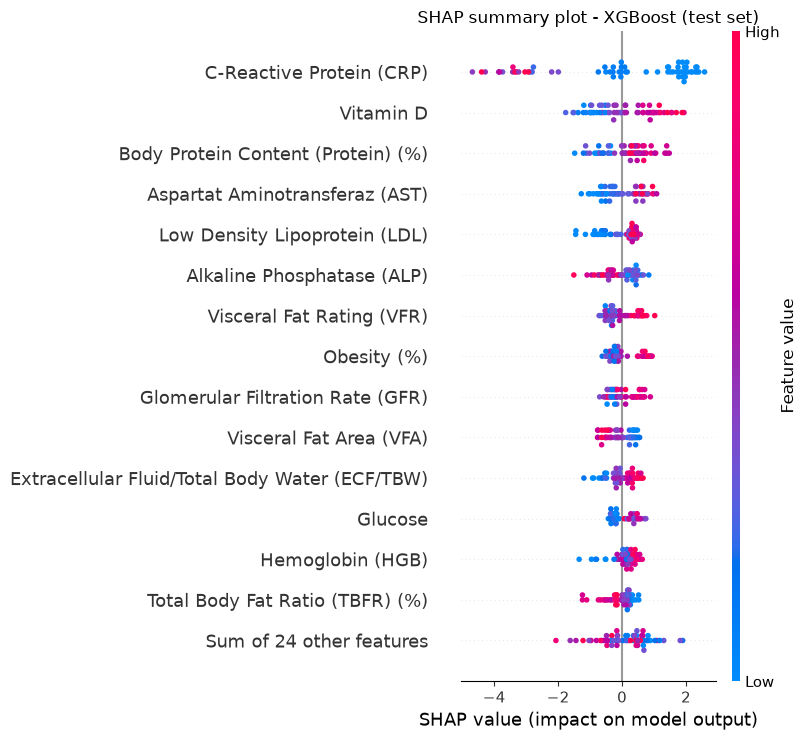

In [6]:
#beeswarm / summary plot
plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('SHAP summary plot - XGBoost (test set)')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'shap_beeswarm.png'), dpi=300, bbox_inches='tight')
plt.show()

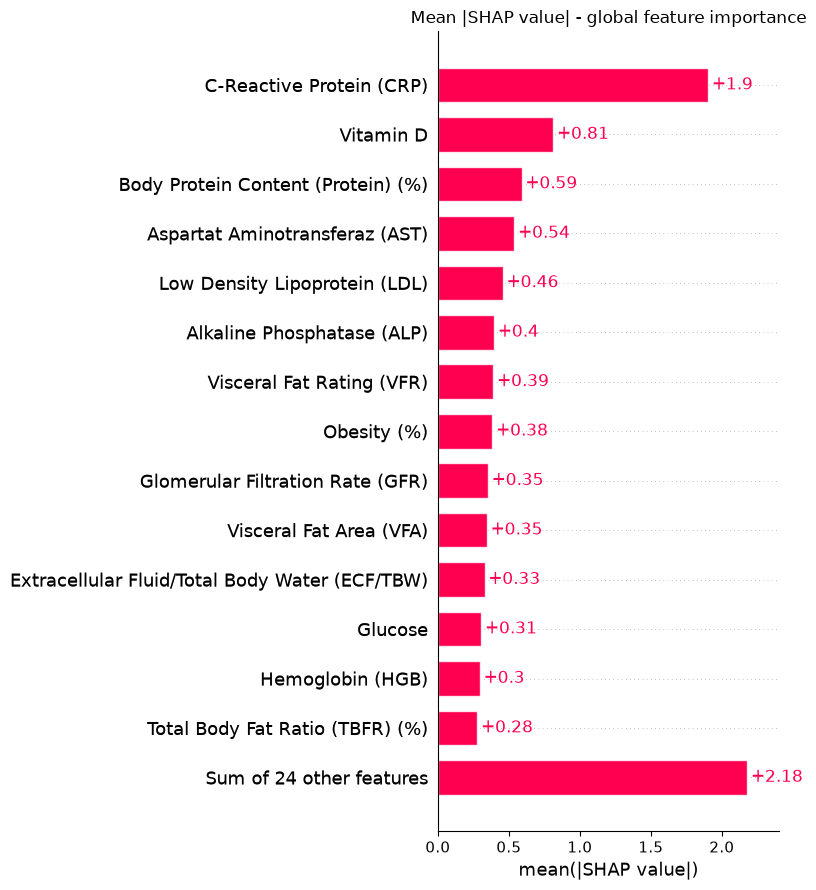

,Mean |SHAP|
C-Reactive Protein (CRP),1.904
Vitamin D,0.813
Body Protein Content (Protein) (%),0.591
Aspartat Aminotransferaz (AST),0.539
Low Density Lipoprotein (LDL),0.458
Alkaline Phosphatase (ALP),0.397
Visceral Fat Rating (VFR),0.391
Obesity (%),0.384
Glomerular Filtration Rate (GFR),0.353
Visceral Fat Area (VFA),0.346


In [7]:
#bar plot of the global importance
plt.figure()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('Mean |SHAP value| - global feature importance')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'shap_bar.png'), dpi=300, bbox_inches='tight')
plt.show()

#table of the global ranking (used later for the comparison)
shap_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0), index=feature_names
).sort_values(ascending=False)
shap_importance.head(10).round(3).to_frame('Mean |SHAP|')

**Reading the global plots:** see the clinical interpretation in Section 8. The direction of each effect is read from the colour in the beeswarm: if red dots (high values) are on the right, high values of that feature increase the predicted risk of gallstones.

## 4. SHAP local explanations (waterfall plots)

Global importance does not explain a single decision. We pick three test patients with a clear criterion:

- **True positive (TP):** gallstone patient that the model detects with the highest probability.
- **False negative (FN):** gallstone patient that the model misses (the clinically most dangerous error).
- **False positive (FP):** healthy patient that the model flags as disease.

A waterfall plot starts from the average output E[f(x)] and adds the contribution of each feature until it reaches the output f(x) for that patient. Both values are in log-odds; the probability in the title is sigmoid(f(x)).

In [8]:
results = pd.DataFrame({'y_true': y_test.values, 'y_pred': y_pred, 'p_disease': y_proba})

tp_idx = results[(results.y_true == 1) & (results.y_pred == 1)].p_disease.idxmax()
fn_cands = results[(results.y_true == 1) & (results.y_pred == 0)]
fp_cands = results[(results.y_true == 0) & (results.y_pred == 1)]
#the most confident mistakes are the most informative ones
fn_idx = fn_cands.p_disease.idxmin()
fp_idx = fp_cands.p_disease.idxmax()

selected = {'True positive': tp_idx, 'False negative': fn_idx, 'False positive': fp_idx}
for label, i in selected.items():
    print(f"{label:15s} -> test row {i}, P(disease) = {results.p_disease[i]:.3f}")

True positive   -> test row 6, P(disease) = 1.000
False negative  -> test row 34, P(disease) = 0.017
False positive  -> test row 47, P(disease) = 0.986


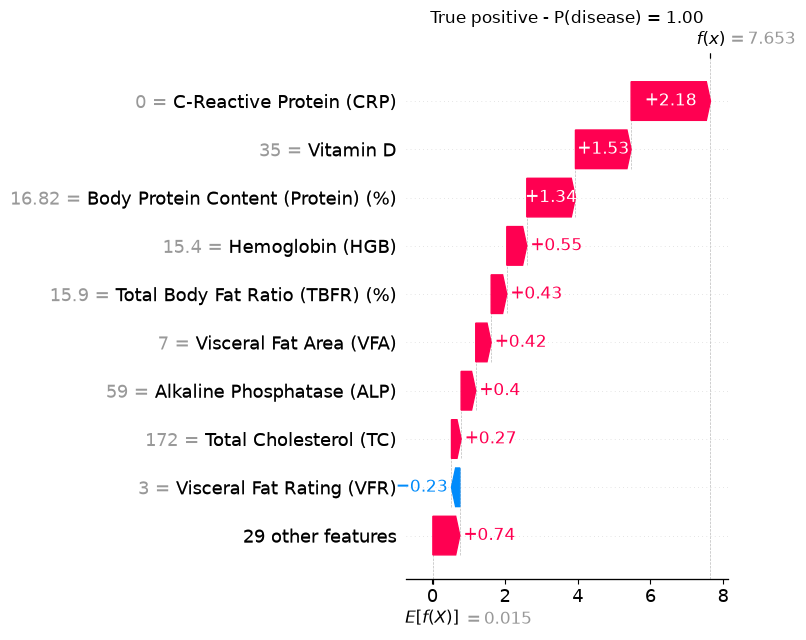

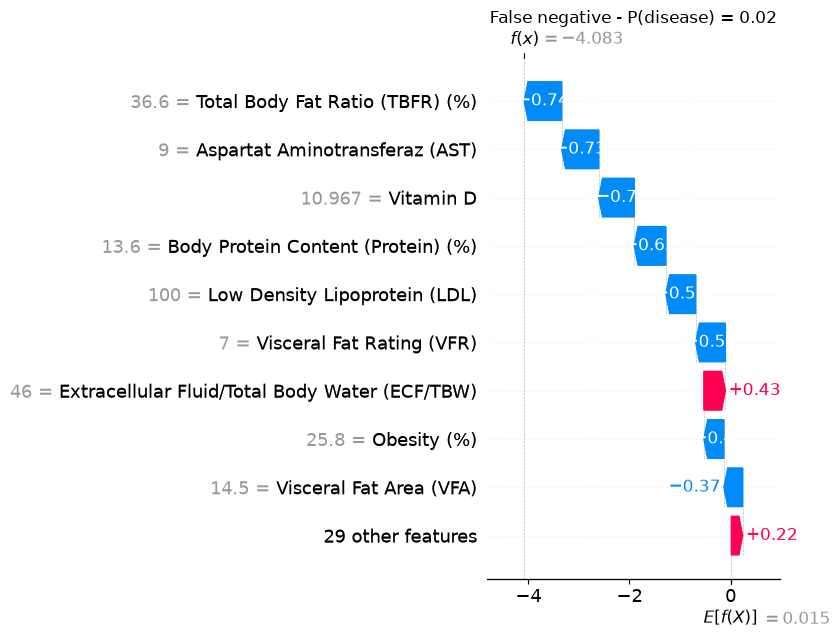

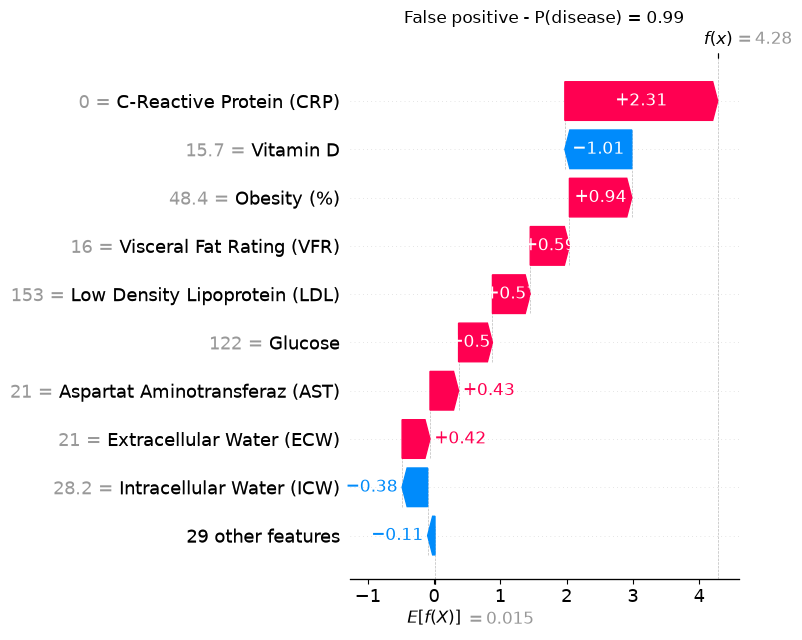

In [9]:
for label, i in selected.items():
    plt.figure()
    shap.plots.waterfall(shap_values[i], max_display=10, show=False)
    plt.title(f'{label} - P(disease) = {results.p_disease[i]:.2f}')
    plt.tight_layout()
    fname = 'shap_waterfall_' + label.lower().replace(' ', '_') + '.png'
    plt.savefig(os.path.join(fig_dir, fname), dpi=300, bbox_inches='tight')
    plt.show()

**Reading the waterfalls:** red bars push the prediction towards gallstones, blue bars towards healthy. For the false negative and the false positive, the bars show which feature values misled the model, which is useful for discussing its limitations.

## 5. SHAP dependence plots

For the three most important features we plot the SHAP value against the original feature value. This shows the **shape** of the effect (increasing, decreasing, threshold) and possible interactions (colour = the feature SHAP finds most interacting).

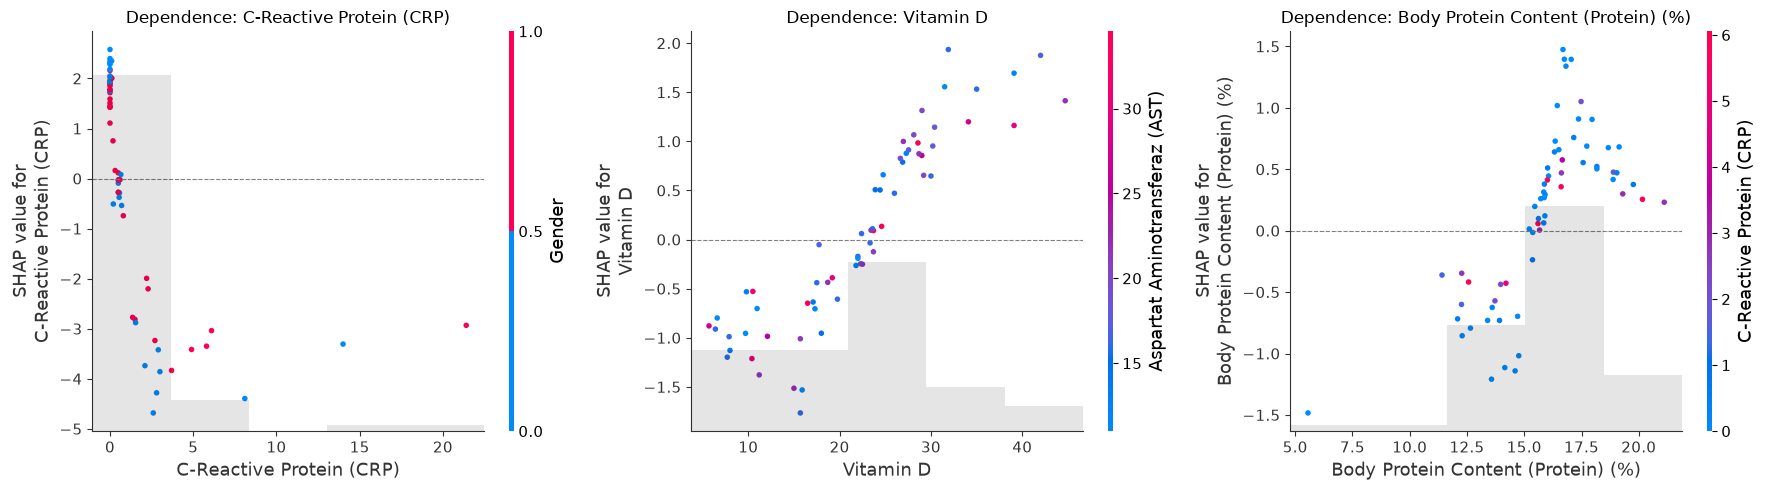

In [10]:
top3 = shap_importance.index[:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, top3):
    j = feature_names.index(feat)
    shap.plots.scatter(shap_values[:, j], color=shap_values, ax=ax, show=False)
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(f'Dependence: {feat}')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'shap_dependence_top3.png'), dpi=300, bbox_inches='tight')
plt.show()

## 6. LIME local explanations

LIME explains one prediction with a **local linear regression**. For the patient being explained it:

1. creates many perturbed copies of the patient (new samples drawn around their values);
2. asks the pipeline for the probability of disease of every copy;
3. gives each copy a **weight** that is larger the closer it is to the original patient;
4. fits a weighted linear regression, P(disease) ≈ b + w1·x1 + ... + wk·xk, on those copies.

The coefficients w of that regression are the explanation: a positive w pushes the probability towards disease near this patient. Continuous features are discretized into intervals (e.g. "CRP > 1.20"), so each x is 1 if the patient's value is in that interval and 0 otherwise. The R² of the local regression (`score`) tells how well the linear approximation fits the model around the patient.

LIME is model-agnostic, so we explain the **whole pipeline** on the original features (the pipeline scales internally, as Member 1 specified: do not apply `scaler.joblib` before `best_model.joblib`).

We explain the same three patients and check whether LIME and SHAP agree on the main features.

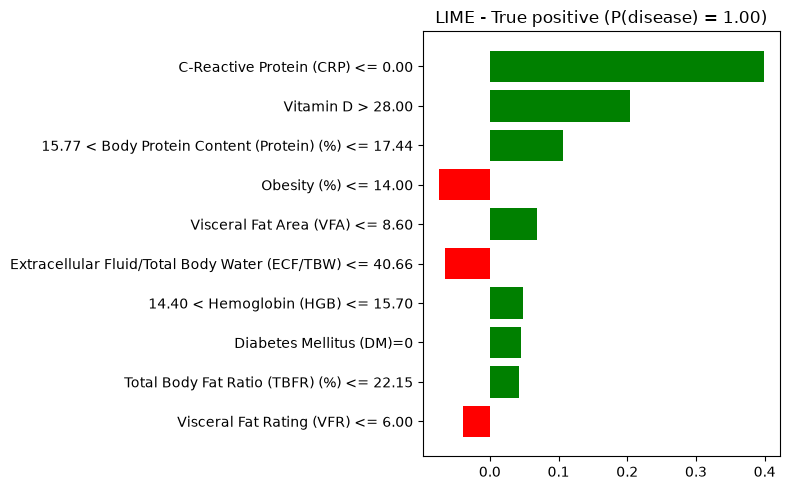

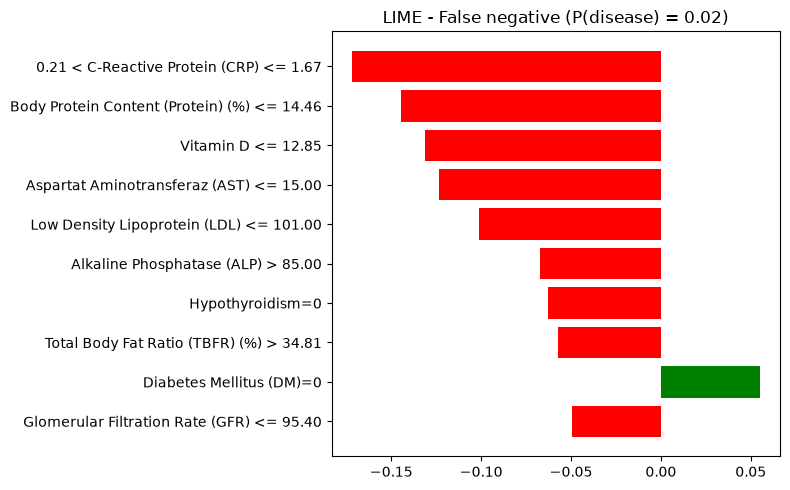

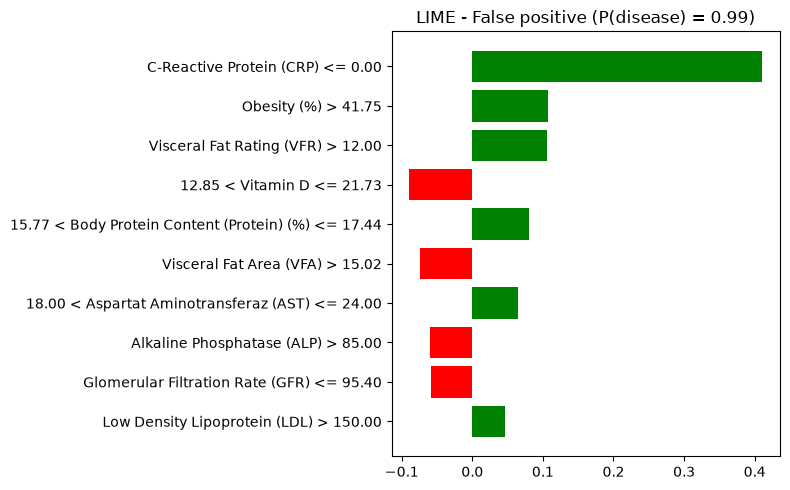

In [11]:
binary_feats = [c for c in X_train.columns if X_train[c].nunique() <= 2]

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['Healthy', 'Disease'],
    categorical_features=[X_train.columns.get_loc(c) for c in binary_feats],
    mode='classification',
    discretize_continuous=True,
    random_state=42
)

def predict_fn(arr):
    #LIME passes numpy arrays; the pipeline expects a DataFrame with the original columns
    return best_pipeline.predict_proba(pd.DataFrame(arr, columns=X_train.columns))

lime_top, lime_r2 = {}, {}
for label, i in selected.items():
    exp = lime_explainer.explain_instance(
        X_test.iloc[i].values, predict_fn, num_features=10, labels=(1,)
    )
    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(8, 5)
    plt.title(f'LIME - {label} (P(disease) = {results.p_disease[i]:.2f})')
    plt.tight_layout()
    fname = 'lime_' + label.lower().replace(' ', '_') + '.png'
    plt.savefig(os.path.join(fig_dir, fname), dpi=300, bbox_inches='tight')
    plt.show()
    lime_top[label] = exp.as_list(label=1)
    lime_r2[label] = exp.score

In [12]:
#agreement between SHAP and LIME: overlap of the top-5 features for each patient
def lime_feature(rule):
    #LIME rules look like 'C-Reactive Protein (CRP) > 1.20'; recover the feature name
    for f in sorted(X_train.columns, key=len, reverse=True):
        if f in rule:
            return f
    return rule

rows = []
for label, i in selected.items():
    shap_top5 = pd.Series(np.abs(shap_values.values[i]), index=feature_names).nlargest(5).index.tolist()
    lime_top5 = [lime_feature(r) for r, w in lime_top[label][:5]]
    rows.append({
        'Patient': label,
        'SHAP top 5': ', '.join(shap_top5),
        'LIME top 5': ', '.join(lime_top5),
        'Common': len(set(shap_top5) & set(lime_top5)),
        'LIME local R²': round(lime_r2[label], 2)
    })
agreement = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', None)
agreement

,Patient,SHAP top 5,LIME top 5,Common,LIME local R²
0,True positive,"C-Reactive Protein (CRP), Vitamin D, Body Protein Content (Protein) (%), Hemoglobin (HGB), Total Body Fat Ratio (TBFR) (%)","C-Reactive Protein (CRP), Vitamin D, Body Protein Content (Protein) (%), Obesity (%), Visceral Fat Area (VFA)",3,0.36
1,False negative,"Total Body Fat Ratio (TBFR) (%), Aspartat Aminotransferaz (AST), Vitamin D, Body Protein Content (Protein) (%), Low Density Lipoprotein (LDL)","C-Reactive Protein (CRP), Body Protein Content (Protein) (%), Vitamin D, Aspartat Aminotransferaz (AST), Low Density Lipoprotein (LDL)",4,0.15
2,False positive,"C-Reactive Protein (CRP), Vitamin D, Obesity (%), Visceral Fat Rating (VFR), Low Density Lipoprotein (LDL)","C-Reactive Protein (CRP), Obesity (%), Visceral Fat Rating (VFR), Vitamin D, Body Protein Content (Protein) (%)",4,0.36


## 7. Robustness of the ranking: four different methods

If different explanation methods (and even different models) point to the same features, the finding is more trustworthy. We compare:

1. **SHAP** mean |value| for XGBoost (Section 3).
2. **Permutation importance** of the XGBoost pipeline on the test set: each feature is randomly shuffled 30 times, which breaks its relation with the target, and we measure how much the ROC-AUC drops. A large drop means the model depends on that feature.
3. **Logistic Regression weights.** Logistic regression computes a linear score z = w1·x1 + ... + wk·xk + b and passes it through the sigmoid. Because the continuous features are standardized, the size |w| of each weight is comparable between features, and its sign says whether the feature raises (+) or lowers (−) the risk. This is the model that obtained the best holdout F1-score in Member 1's notebook, trained with the same configuration.
4. **Single Decision Tree** with `criterion='entropy'`: the importance of a feature is the total information gain of all the splits that use it. We limit the depth to 4 so that the tree stays readable and does not memorize the training set.

We also compute the Spearman rank correlation between the rankings. The depth-4 tree only uses a few features; all the features it does not use have importance 0 and share the same (last) rank.

In [13]:
#2. permutation importance on the full pipeline (original features, test set)
perm = permutation_importance(
    best_pipeline, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=42
)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns)

#3. logistic regression with the same preprocessing as Member 1
continuous_cols = [c for c in X.columns if X[c].nunique() > 2 and X[c].dtype in ['int64', 'float64']]
lr_pipeline = Pipeline([
    ('preprocessor', ColumnTransformer([('num', StandardScaler(), continuous_cols)], remainder='passthrough')),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])
lr_pipeline.fit(X_train, y_train)
print(f"Logistic Regression holdout F1: {f1_score(y_test, lr_pipeline.predict(X_test)):.4f} (expected 0.8056)")

lr_names = [n.split('__', 1)[1] for n in lr_pipeline.named_steps['preprocessor'].get_feature_names_out()]
lr_coef = pd.Series(lr_pipeline.named_steps['classifier'].coef_[0], index=lr_names)

#4. single decision tree (entropy = information gain), scaling is not needed for trees
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
print(f"Decision Tree (depth 4) holdout F1: {f1_score(y_test, dt_model.predict(X_test)):.4f}")
dt_importance = pd.Series(dt_model.feature_importances_, index=X_train.columns)

ranking = pd.DataFrame({
    'SHAP (XGB)': shap_importance,
    'Permutation (XGB)': perm_importance,
    '|LR coefficient|': lr_coef.abs(),
    'Tree (entropy)': dt_importance,
    'LR sign': np.sign(lr_coef).map({1.0: '+ (risk)', -1.0: '- (protective)', 0.0: '0'})
})
methods = ['SHAP (XGB)', 'Permutation (XGB)', '|LR coefficient|', 'Tree (entropy)']
ranks = ranking[methods].rank(ascending=False, method='min').astype(int)
ranks.columns = ['Rank SHAP', 'Rank Permutation', 'Rank LR', 'Rank Tree']
comparison = pd.concat([ranks, ranking['LR sign']], axis=1).sort_values('Rank SHAP')
comparison.head(10)

Logistic Regression holdout F1: 0.8056 (expected 0.8056)
Decision Tree (depth 4) holdout F1: 0.7164


,Rank SHAP,Rank Permutation,Rank LR,Rank Tree,LR sign
C-Reactive Protein (CRP),1,1,3,1,- (protective)
Vitamin D,2,2,11,2,+ (risk)
Body Protein Content (Protein) (%),3,23,19,10,+ (risk)
Aspartat Aminotransferaz (AST),4,7,8,8,+ (risk)
Low Density Lipoprotein (LDL),5,38,27,10,+ (risk)
Alkaline Phosphatase (ALP),6,8,30,10,- (protective)
Visceral Fat Rating (VFR),7,36,15,10,+ (risk)
Obesity (%),8,3,38,9,+ (risk)
Glomerular Filtration Rate (GFR),9,5,37,10,- (protective)
Visceral Fat Area (VFA),10,24,23,5,- (protective)


In [14]:
print("Spearman rank correlation between methods (all 38 features):")
print(ranking[methods].corr(method='spearman').round(2))

#the depth-4 tree uses only a few features (the rest have importance 0), so we look at its top 5
print(f"\nFeatures used by the decision tree: {(dt_importance > 0).sum()} of {len(dt_importance)}")
print(f"Decision tree top 5: {dt_importance.nlargest(5).index.tolist()}")

top10 = {m: set(ranking[m].nlargest(10).index) for m in ['SHAP (XGB)', 'Permutation (XGB)', '|LR coefficient|']}
consensus = set.intersection(*top10.values())
print(f"\nFeatures in the top 10 of SHAP, permutation and LR: {sorted(consensus)}")

comparison.to_csv(os.path.join(fig_dir, 'feature_ranking_comparison.csv'))

Spearman rank correlation between methods (all 38 features):
                   SHAP (XGB)  Permutation (XGB)  |LR coefficient|  \
SHAP (XGB)               1.00               0.30             -0.05   
Permutation (XGB)        0.30               1.00             -0.02   
|LR coefficient|        -0.05              -0.02              1.00   
Tree (entropy)           0.30               0.29              0.15   

                   Tree (entropy)  
SHAP (XGB)                   0.30  
Permutation (XGB)            0.29  
|LR coefficient|             0.15  
Tree (entropy)               1.00  

Features used by the decision tree: 9 of 38
Decision tree top 5: ['C-Reactive Protein (CRP)', 'Vitamin D', 'Creatinine', 'Hyperlipidemia', 'Visceral Fat Area (VFA)']

Features in the top 10 of SHAP, permutation and LR: ['Aspartat Aminotransferaz (AST)', 'C-Reactive Protein (CRP)']


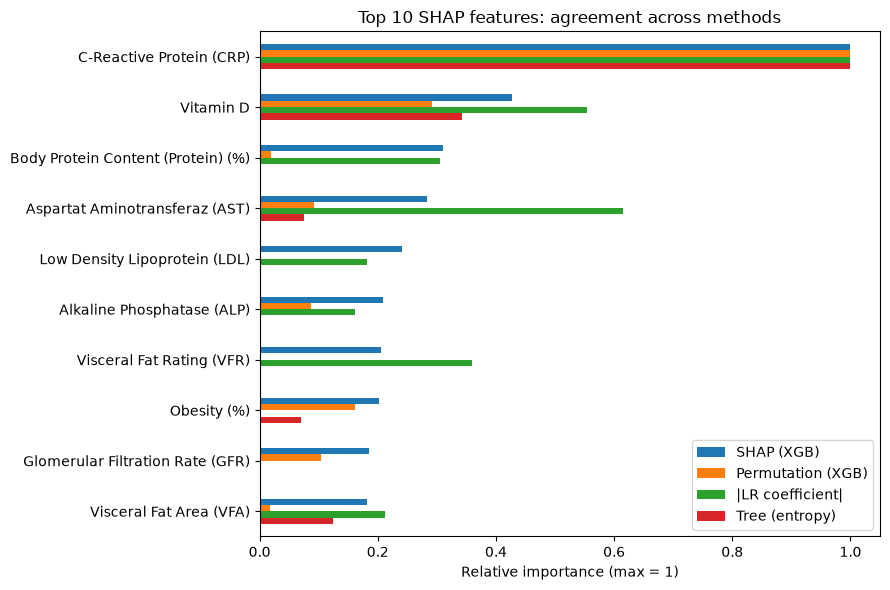

In [15]:
#visual comparison of the top 10 SHAP features across methods (normalized to 0-1)
top10_shap = shap_importance.index[:10]
norm = ranking.loc[top10_shap, methods]
norm = norm.clip(lower=0) / norm.clip(lower=0).max()
norm.plot(kind='barh', figsize=(9, 6))
plt.gca().invert_yaxis()
plt.xlabel('Relative importance (max = 1)')
plt.title('Top 10 SHAP features: agreement across methods')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'ranking_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## 8. Clinical interpretation and contrast with the literature

**Main finding (robust):** the two most important features for the model are **C-Reactive Protein (CRP)** and **Vitamin D**. CRP is first for SHAP, permutation importance and the entropy decision tree (which also puts Vitamin D second), it is in the top 10 of SHAP, permutation importance and Logistic Regression together with AST, and SHAP and LIME agree on 3 to 4 of the top 5 features for each explained patient. These features are followed by body-composition variables (body protein content, visceral fat rating, visceral fat area, obesity %) and liver/lipid laboratory values (AST, ALP, LDL).

**Agreement between methods:** SHAP and permutation importance for XGBoost agree on the very top (CRP, Vitamin D) but only moderately overall (Spearman 0.30), the single decision tree correlates similarly with both (0.30 and 0.29), and the Logistic Regression ranking is almost unrelated (Spearman about 0). This is expected with many correlated features: tree models and linear models distribute the importance of correlated body-composition variables differently. The conclusion should therefore be stated at the level of **CRP, Vitamin D and the body-composition group**, not as an exact ranking of every feature.

**Contrast with the literature:** other studies on this same UCI dataset also place CRP and Vitamin D at the top: a Bayesian (BART) analysis selected "CRP, Vitamin D, ECF, BM, Hyperlipidemia, VFA, HGB, DM, and CAD" ([arXiv:2506.14561](https://arxiv.org/abs/2506.14561)), and a SHAP-based study reports CRP, Vitamin D and Obesity as the three most impactful features. Our model therefore agrees with the literature on *which* features matter. 

**Reference paper (Esen et al., 2024):** the authors highlight **Vitamin D, CRP, total body water and lean mass** as the most important features (abstract and Table 2), so our two most important features coincide with theirs. Their best model was Gradient Boosting with 85.42% accuracy (Table 3: precision 0.91, recall 0.81, F1 0.86, AUC 0.85). Our XGBoost, without hyperparameter tuning, reaches 0.77 accuracy and the same AUC (0.85) on the holdout set.

**Label encoding and direction of the effects.** The sources disagree on the coding of `Gallstone Status`: the UCI page states "Gallstones present (0), absent (1)", while the reference paper states "1 represents a person with gallstones; otherwise 0" (Section 2). The group decided to follow the UCI documentation, which is also supported by the class counts (161 patients with gallstones are reported and 161 patients have the value 0).

Under this encoding the model associates **higher CRP with *Healthy*** and **higher Vitamin D with *Disease***, and the raw data show the same pattern: the gallstone group has mean CRP 0.46 vs 3.27 in the control group (median 0.00 vs 1.29) and mean Vitamin D 24.9 vs 17.8. This is the opposite of what is usually expected clinically (inflammation and Vitamin D deficiency are associated with gallstones). A possible explanation, which we cannot verify with this dataset, is the composition of the sample: the controls are not healthy volunteers but patients of the same Internal Medicine Outpatient Clinic (the paper does not state why they attended), so other conditions may raise their CRP and lower their Vitamin D, while many gallstone patients have no active inflammation at the time of measurement. **Therefore we report CRP and Vitamin D as the most informative features, but we do not claim a causal or clinical direction for them**; if the encoding of the paper were the correct one, the importance ranking would stay the same and only the direction of every effect would flip.

## 9. Limitations of the explanations

### 9.1 Correlated body-composition features

Many bioimpedance features measure almost the same thing (body size, fat or water). We check it with the Pearson correlation matrix of the main body-composition features on the training set.

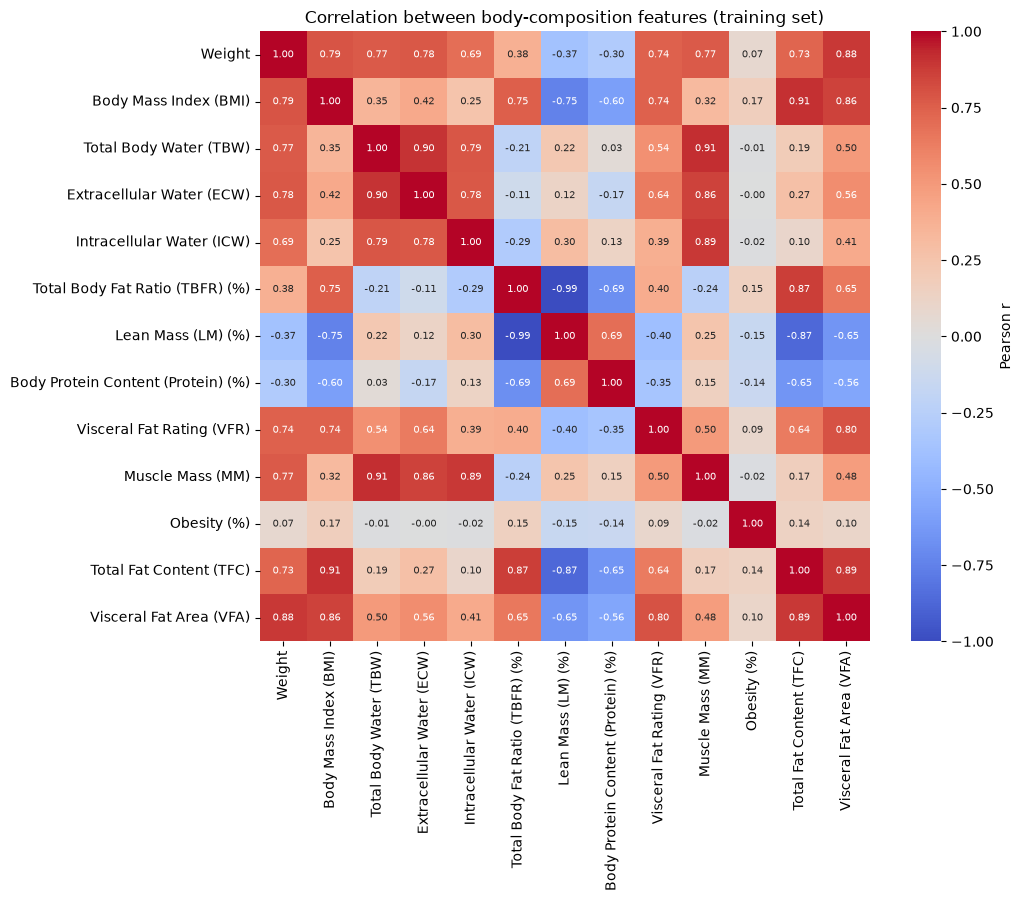

Pairs with |r| > 0.8: 12 of 78


In [16]:
body_cols = ['Weight', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Extracellular Water (ECW)',
             'Intracellular Water (ICW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
             'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Muscle Mass (MM)',
             'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)']
corr = X_train[body_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True,
            annot_kws={'size': 7}, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation between body-composition features (training set)')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'body_composition_correlation.png'), dpi=300, bbox_inches='tight')
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print(f"Pairs with |r| > 0.8: {(upper.abs() > 0.8).sum()} of {len(upper)}")

### 9.2 Limitations

- **Correlated features share the credit.** As the matrix shows, weight, BMI, fat mass, visceral fat, muscle mass and body water are strongly correlated (12 pairs with |r| > 0.8; Obesity (%) is the exception, almost uncorrelated with the rest); SHAP and permutation importance can split or move importance between them, so the importance of a *group* of body-composition features is more reliable than the exact rank of one of them. PCA could merge them into a few uncorrelated components, but those components are no longer recognizable clinical measurements, so the explanations would be harder to interpret; we therefore keep the original features.
- **Importance is not causality.** SHAP explains the model, not the disease. A laboratory value can be important because it reflects the presence of gallstones (e.g. inflammation), not because it causes them.
- **Small single-centre sample.** 319 patients from one hospital and 64 test patients: rankings can change with another split or another population. No external validation cohort is available.
- **No hyperparameter optimization** was performed (Member 1 used default configurations), so the explained model is not necessarily the best possible XGBoost.
- **LIME is stochastic and local.** Its explanations depend on the random perturbations and on the discretization of the features; we fixed `random_state=42` for reproducibility.
- **Why not a neural network.** Neural networks need large amounts of data to learn their many weights, and their decisions are harder to explain. With 319 patients and tabular data, tree ensembles such as XGBoost are a sounder choice, and `TreeExplainer` computes their SHAP values exactly instead of approximating them.
- The model is a research exercise and is **not a validated clinical tool**.

## References

- Esen, I., Arslan, H., Esen, S. A., Gülşen, M., Kültekin, N., & Özdemir, O. (2024). Early prediction of gallstone disease with a machine learning-based method from bioimpedance and laboratory data. *Medicine*. https://doi.org/10.1097/md.0000000000037258
- Gallstone dataset, UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/1150/gallstone-1 (CC BY 4.0).
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30* (SHAP).
- Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2, 56–67 (TreeExplainer).
- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). "Why should I trust you?": Explaining the predictions of any classifier. *Proceedings of the 22nd ACM SIGKDD* (LIME).
- Bayesian Hybrid Machine Learning of Gallstone Risk (2025), arXiv:2506.14561 — a second study on the same dataset, used for comparison of the important features.